In [39]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [40]:
import pandas as pd 
import matplotlib.pyplot as plt
import yfinance as yf


In [41]:
basket = ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'META']

In [42]:
data = yf.download(
    basket,
    start='2010-01-01',
    auto_adjust=False,
    actions=True
)

prices = data['Close'][basket].dropna()

splits = data['Stock Splits'][basket].reindex(prices.index).fillna(0)

split_factors = splits.replace(0, 1).iloc[1:].prod()


tech_etf = prices.mul(split_factors, axis=1).sum(axis=1).to_frame(name='Price')

[*********************100%***********************]  6 of 6 completed


Text(0, 0.5, 'Combined Stock Price (USD)')

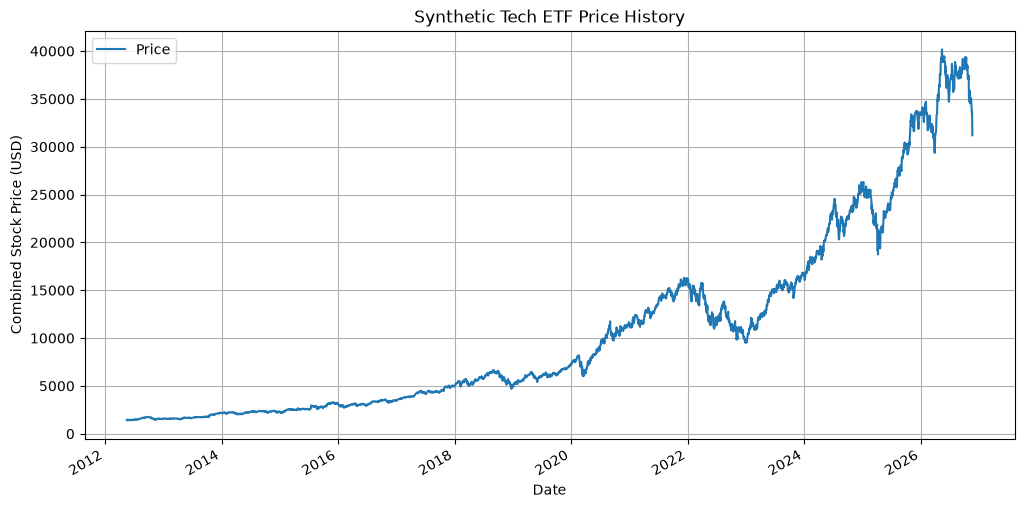

In [43]:

ax = tech_etf.plot(
    title='Synthetic Tech ETF Price History',
    figsize=(12, 6),
    grid=True
)

ax.set_xlabel('Date')
ax.set_ylabel('Combined Stock Price (USD)')

Now we will look at the relationships between the rolling averages over some general time amount.

two hundered just gives us some general baseline whereas the twenty, ten and five can give us some general "momentum" figure that we might be able to exploit.

In [44]:
tech_etf['MA_5'] = tech_etf['Price'].rolling(5).mean()
tech_etf['MA_10'] = tech_etf['Price'].rolling(10).mean()
tech_etf['MA_20'] = tech_etf['Price'].rolling(20).mean()
tech_etf['MA_200'] = tech_etf['Price'].rolling(200).mean()
tech_etf['5_20_MA_Diff'] = tech_etf['MA_5'] - tech_etf['MA_20']

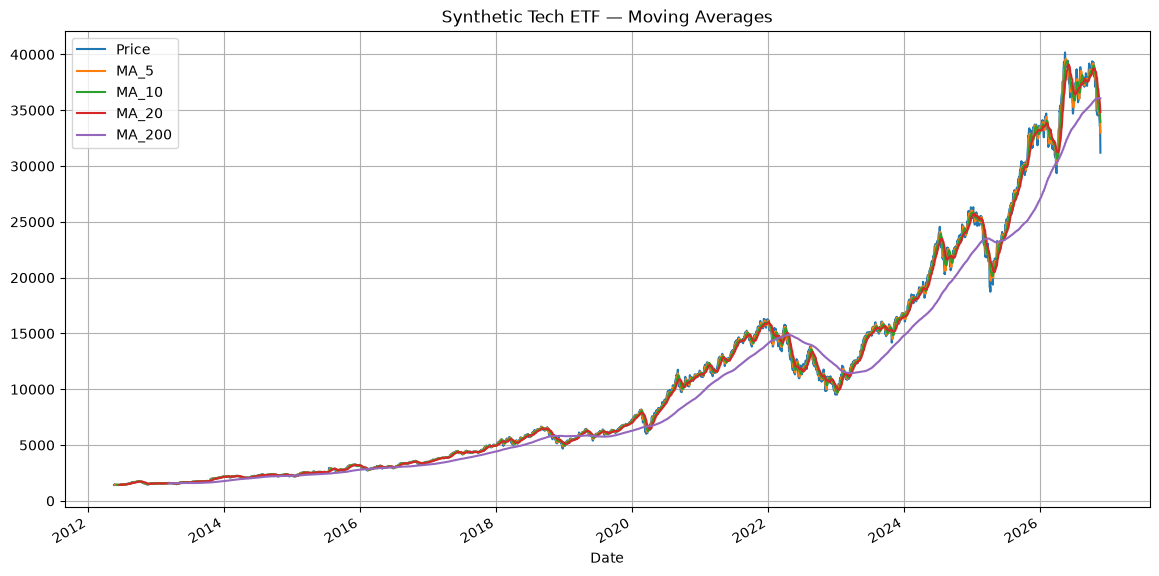

In [45]:
tech_etf[['Price', 'MA_5', 'MA_10', 'MA_20', 'MA_200']].plot(
    figsize=(14, 7),
    title='Synthetic Tech ETF — Moving Averages',
    grid=True
)

plt.show()

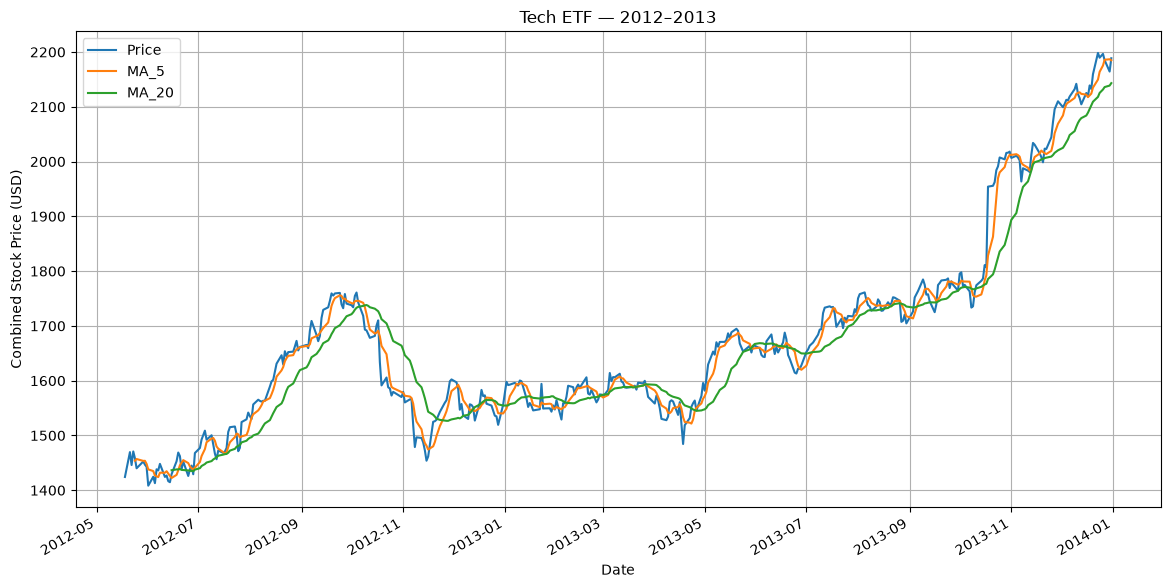

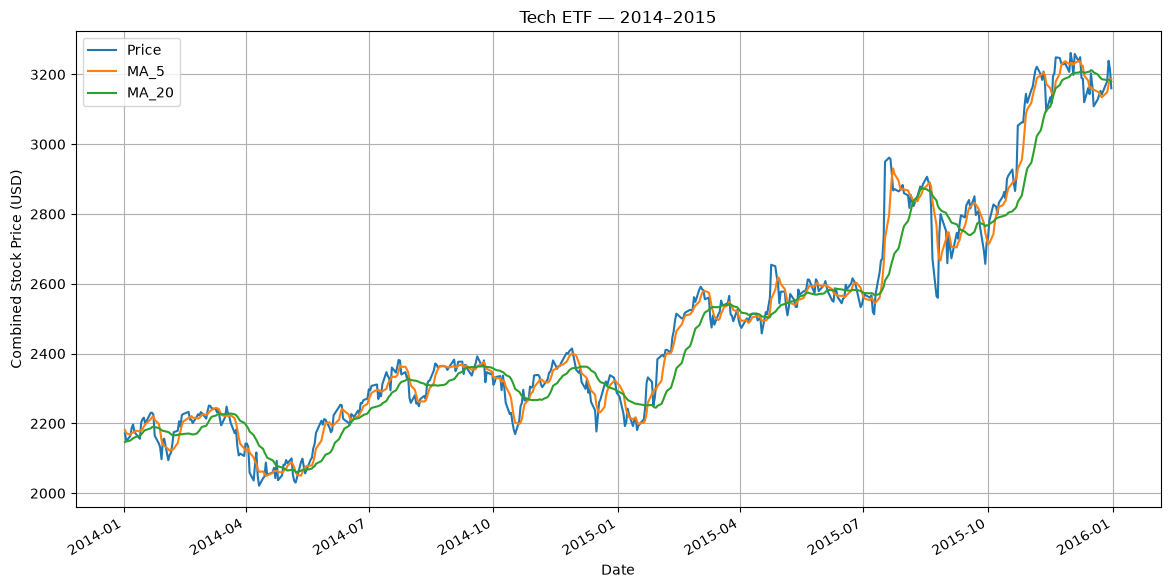

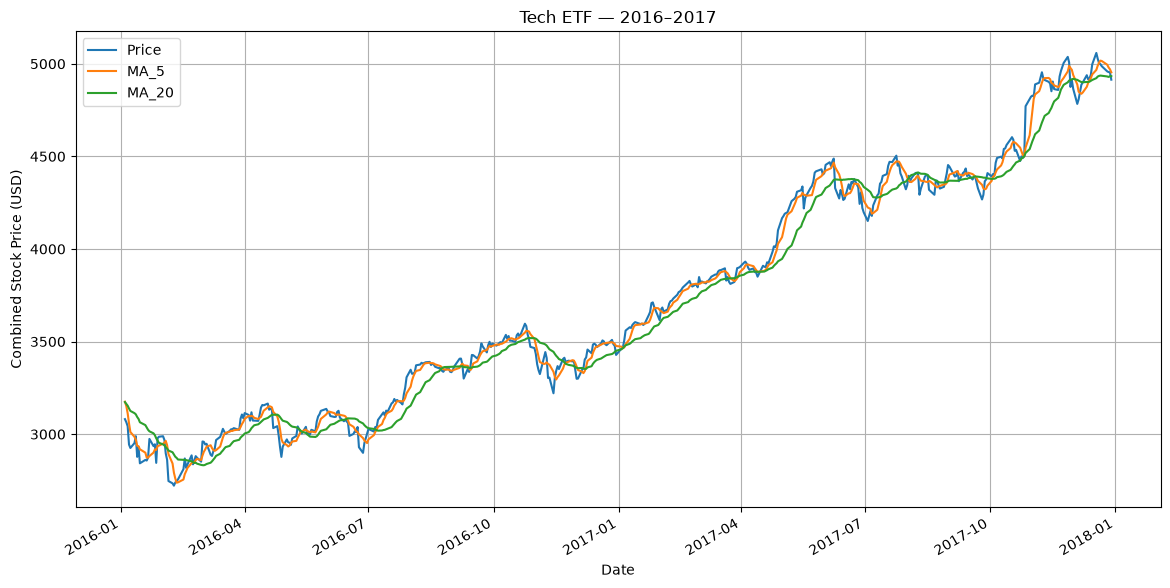

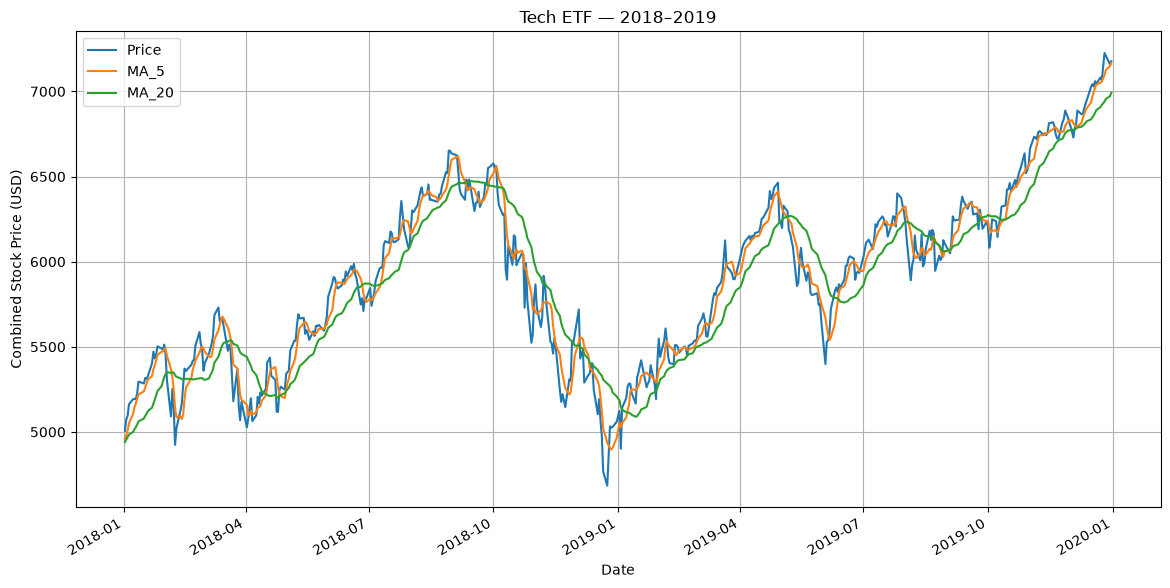

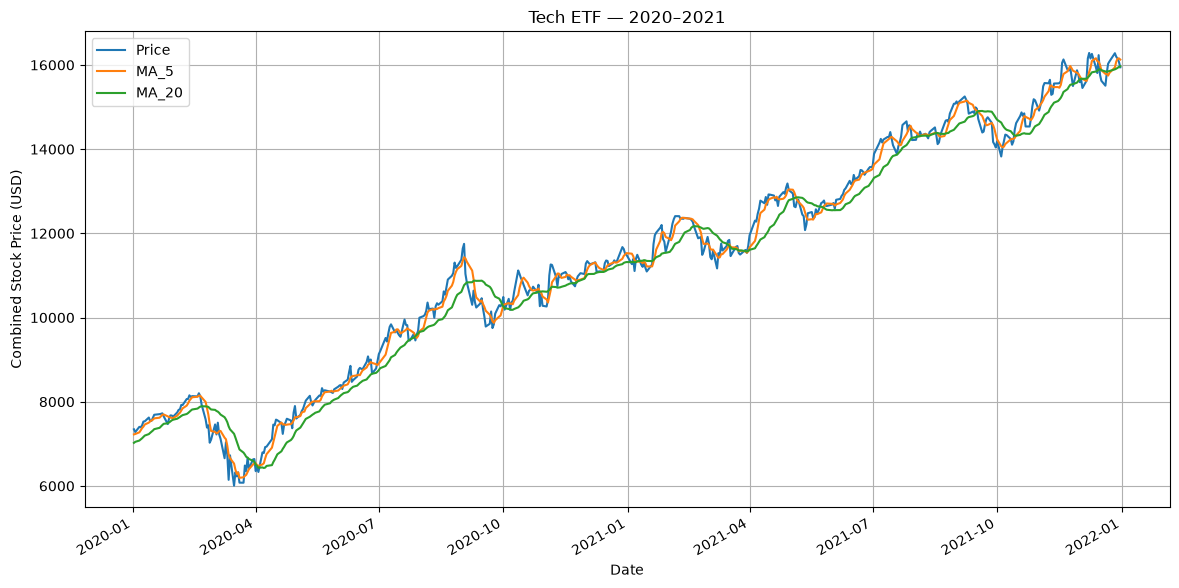

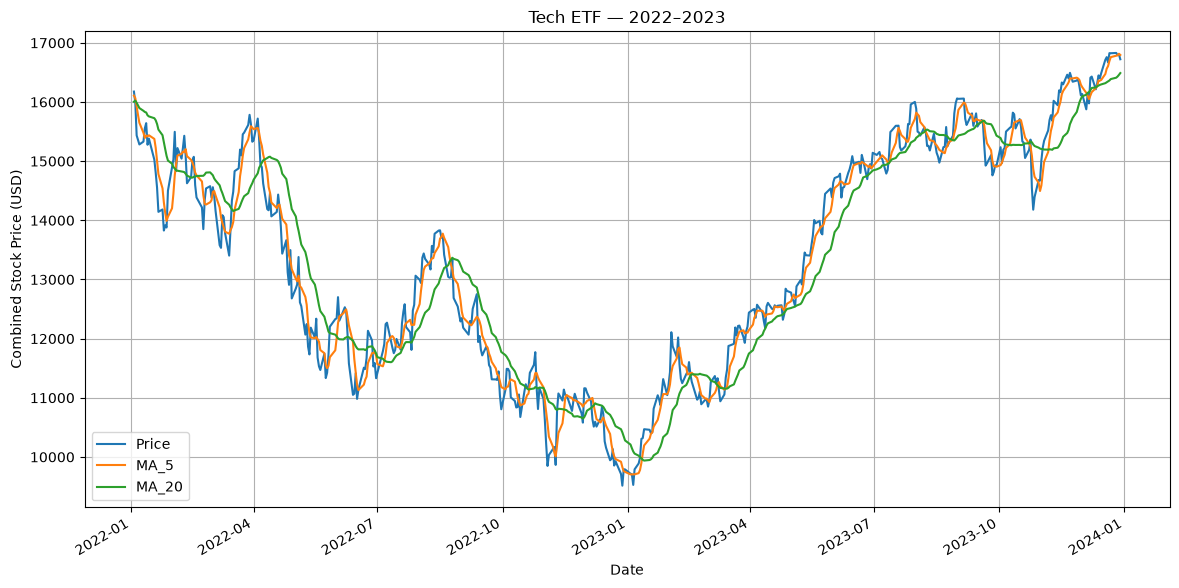

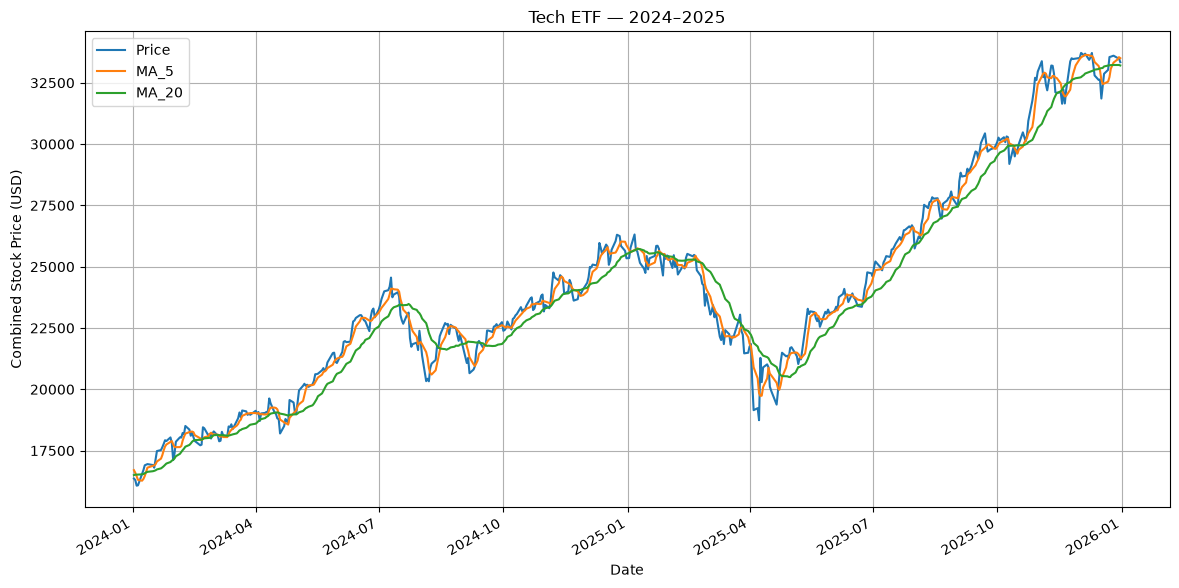

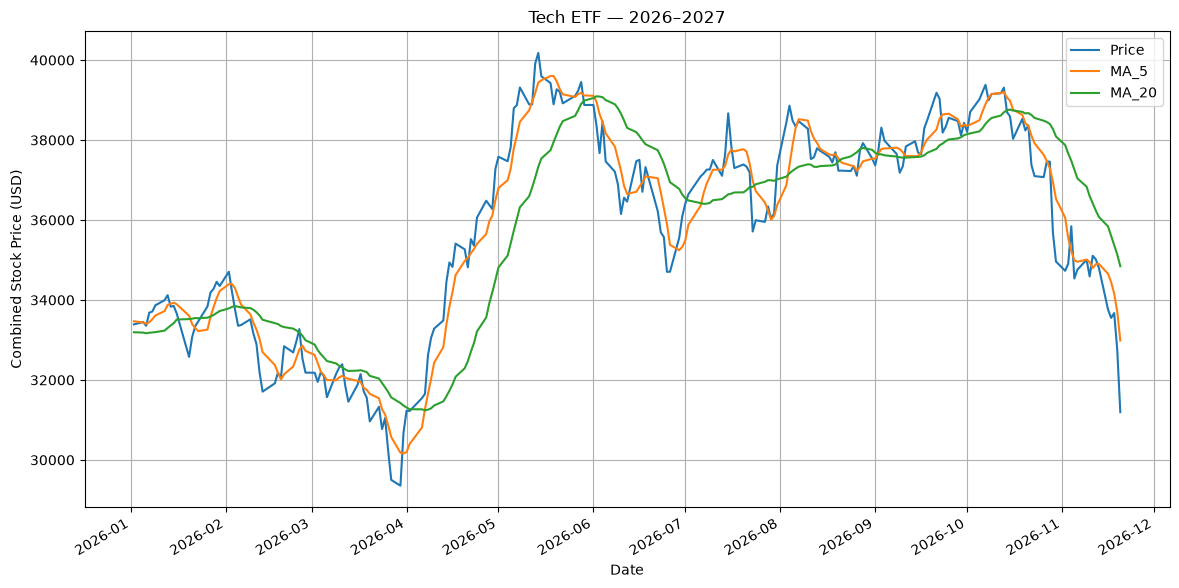

In [46]:
import matplotlib.pyplot as plt

start_year = tech_etf.index.min().year
end_year = tech_etf.index.max().year

for year in range(start_year, end_year + 1, 2):

    period = tech_etf.loc[str(year):str(year + 1)]

    if period.empty:
        continue

    period[['Price', 'MA_5', 'MA_20']].plot(
        figsize=(14, 7),
        title=f'Tech ETF — {year}–{year + 1}',
        grid=True
    )

    plt.ylabel('Combined Stock Price (USD)')
    plt.xlabel('Date')
    plt.show()

We will start with a simple strategy: buy when 5-day MA crosses above the 20-day MA. Sell when the 5-day MA crosses below the 20-day MA. Otherwise maintain. $D_t = SMA_{5}(t) - SMA_{20}(t)$, a buy occurs when $D_{t-1} \leq 0$ and $D_t > 0$ and a sell occurs when $D_{t-1} \geq 0$ and $D_t < 0$. 

In [47]:
tech_etf = tech_etf.dropna(subset=['MA_5', 'MA_20']).copy()

tech_etf['5_20_MA_Diff'] = tech_etf['MA_5'] - tech_etf['MA_20']


tech_etf['Trend'] = (
    tech_etf['MA_5'] > tech_etf['MA_20']
).astype(int)


tech_etf['Trend_Change'] = (
    tech_etf['Trend'] - tech_etf['Trend'].shift(1)
)

In [48]:
initial_capital = 10_000


tech_etf['Daily_Return'] = tech_etf['Price'].pct_change().fillna(0)


tech_etf['Position'] = tech_etf['Trend'].shift(2).fillna(0).astype(int)


tech_etf['Trade'] = tech_etf['Position'].diff().abs().fillna(0)


cost_rate = 0.001 


tech_etf['Strategy_Return'] = (
    (1 + tech_etf['Position'] * tech_etf['Daily_Return'])
    * (1 - cost_rate * tech_etf['Trade'])
    - 1
)


tech_etf['Strategy_Value'] = (
    initial_capital * (1 + tech_etf['Strategy_Return']).cumprod()
)


tech_etf['Buy_Hold_Value'] = (
    initial_capital * tech_etf['Price'] / tech_etf['Price'].iloc[0]
)

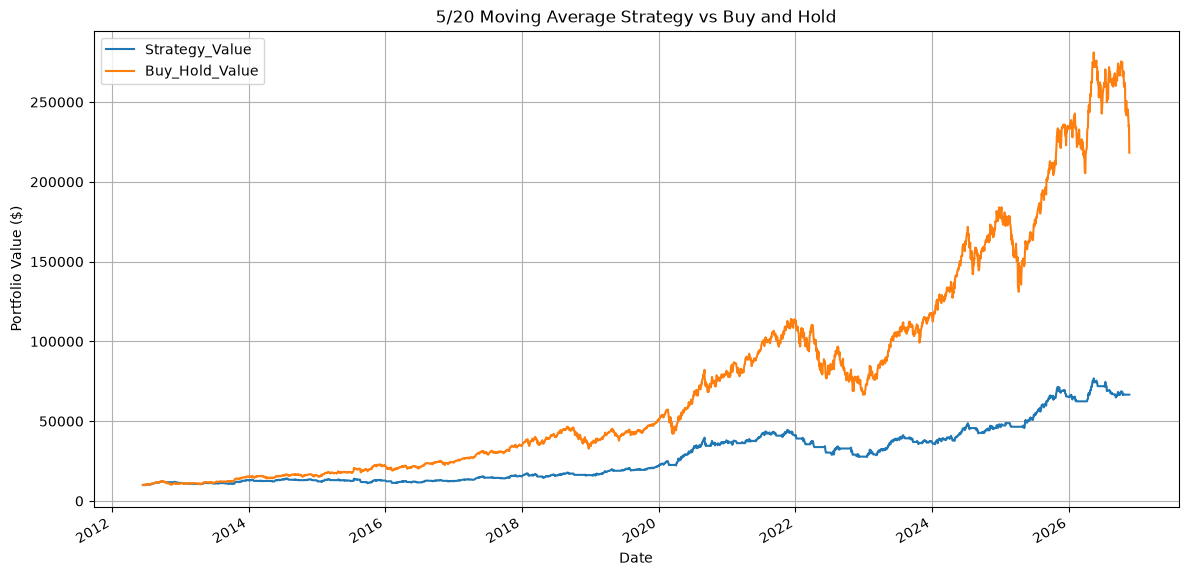

In [49]:
tech_etf[['Strategy_Value', 'Buy_Hold_Value']].plot(
    figsize=(14, 7),
    title='5/20 Moving Average Strategy vs Buy and Hold',
    grid=True
)

plt.xlabel('Date')
plt.ylabel('Portfolio Value ($)')
plt.show()

In [50]:
strategy_return = (
    tech_etf['Strategy_Value'].iloc[-1] / initial_capital - 1
)

buy_hold_return = (
    tech_etf['Buy_Hold_Value'].iloc[-1] / initial_capital - 1
)

number_of_trades = int(tech_etf['Trade'].sum())

print(f"Strategy Total Return: {strategy_return:.2%}")
print(f"Buy & Hold Total Return: {buy_hold_return:.2%}")
print(f"Number of Trades: {number_of_trades}")

Strategy Total Return: 566.38%
Buy & Hold Total Return: 2082.57%
Number of Trades: 214
